Consider a particle restricted to one-dimensional motion along an axis oriented in a vertical fashion, so that we speak of *upward* and *downward* movements. We suppose that the axis is marked off, with a designated origin, so that we may specify its position at time $t$ by giving a single coordinate $X_t$. We fix a time interval $[a,b]$, divided into $n$ subintervals of equal length $\Delta t = (b-a)/n$. At teach time
$$
t_k = a + k\Delta t, \quad k=0,1,\ldots,n-1,
$$
we suppose that our particle experiences an impact from another particle, that will propel it either a distance of $u+h$ units upward, or a distance of $u-h$ units downward, for some $u$ and $h>0$. Thus, the displacements
$$
\Delta X_{t_k} \stackrel{\text{def}}{=} X_{t_{k+1}} - X_{t_k}
$$
are all equal to $u+h$ or $u-h$ ($k=0,1,\ldots,n-1$). We suppose that the upward and downward movements are equiprobable, and that the displacements are independent of each other. This leads us to consider the difference equations
$$
\Delta X_{t_k} = u + h \Delta Z_{t_k}, \tag{1}
$$
for $k=0,1,\ldots,n-1$, where $Z_t$ is a symmetric random walk with initial state $0$. We call $X_t$ a *symmetric random walk with drift*.

These types of random walks model a simplified version of *Brownian motion* in which a particle experiences a single impact per unit of time. For our time interval $[a,b]$ divided into $n$ subintervals, the particle would experience $n$ impacts. But in a true Brownian motion, these impacts are constant, and our ultimate goal is to model the position of a particle undergoing this type of motion. To do this, we let $n\to\infty$ while holding the time interval fixed, which will force $\Delta t\to 0$. However, if each impact propels the particle a fixed and unchanging distance, it is conceivable that the trajectory of the particle might be unbounded. So, to balance the number of particle impacts going to $\infty$, we must correspondingly shrink the distance that each impact propels the particle.

The analysis goes like this. We sum both sides of the difference equation $(1)$ to get
$$
X_b - X_a = \frac{u(b-a)}{\Delta t} + h \sum_{k=0}^{n-1} \Delta Z_{t_k}. \tag{2}
$$
From this, we get formulas for the expectation and variance of the net displacement over the entire interval $[a,b]$:
$$
E(X_b-X_a) = \frac{u(b-a)}{\Delta t}, \qquad V(X_b-X_a) = \frac{h^2(b-a)}{\Delta t}.
$$
In order for the variance to not diverge to $\infty$ as $\Delta t \to 0$, we require that there is a positive real number $\sigma^2$ such that $h^2 = \sigma^2 \Delta t$; similarly, in order for the expectation to not diverge to $\pm \infty$, we require that there is a real number $\mu$ such that $u = \mu \Delta t$. The number $\mu$ is called a *drift coefficient*, while the positive square root $\sigma = \sqrt{\sigma^2}$ is called a *diffusion coefficient*. 

With chosen diffusion and drift coefficients, the difference equation (2) may be rewritten as
$$
X_b - X_a = \mu(b-a) + \sigma \sqrt{\Delta t} \sum_{k=0}^{n-1} \Delta Z_{t_k}.
$$
We will use this equation below to implement $X_t$ from scratch in SigAlg. But for later purposes, it will be convenient to set $W_{t_k} = \sqrt{\Delta t} Z_{t_k}$ for each $k$, and rewrite the difference equation one more time as
$$
X_b-X_a = \mu (b-a) + \sigma (W_b-W_a). \tag{3}
$$
Note that $V(W_b-W_a) = b-a$.

In the code cell below, we illustate the creation of discrete Brownian motions by hand using SigAlg. Note the effects of the drift and diffusion coefficients.

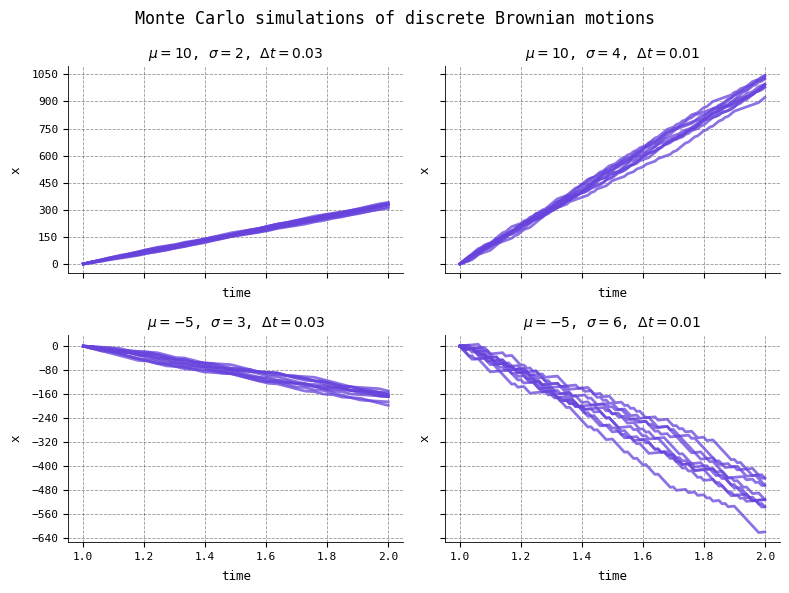

In [59]:
import matplotlib.pyplot as plt
import sigalg as sa

sa.style.use_globally()


def generate_brownian_motion(mu, sigma, X_a, a, b, dt, n_trajectories, random_state):  # noqa: D103
    T = sa.Time.continuous(start=a, stop=b, dt=dt)
    Z = sa.RandomWalk.generate(
        n_trajectories=n_trajectories, index=T, name="Z", random_state=random_state
    )

    return (
        (mu * (b - a) + sigma * (b - a) ** (1 / 2) * Z.increments(forward=False))
        .cumsum()
        .insert_rv(time=a, state=0)
        + X_a
    ).with_name("X")


params = [
    {"mu": 10, "sigma": 2, "X_a": 2, "dt": 0.03},
    {"mu": 10, "sigma": 4, "X_a": 2, "dt": 0.01},
    {"mu": -5, "sigma": 3, "X_a": 0, "dt": 0.03},
    {"mu": -5, "sigma": 6, "X_a": 0, "dt": 0.01},
]

fig, axs = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey="row")

for param, ax in zip(params, axs.flat):
    X = generate_brownian_motion(**param, a=1, b=2, n_trajectories=10, random_state=42)
    X.plot_trajectories(
        ax=ax,
        y_label="x",
        plot_kwargs={"alpha": 0.75},
        title=rf"$\mu={param['mu']}$, $\sigma={param['sigma']}$, $\Delta t={param['dt']}$",
    )
fig.suptitle("Monte Carlo simulations of discrete Brownian motions")
plt.tight_layout()
plt.show()